# Assignment 1

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [1]:
import requests
from bs4 import BeautifulSoup

In [3]:
def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    headers = {
        "User-Agent": "Chrome/120.0.0.0"
    }

    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    response.encoding = 'utf-8'

    soup = BeautifulSoup(response.text, "html.parser")
    return soup.get_text(separator=" ", strip=True)

"""
    Replace the following links with links you wish to parse for this assignemnt.
"""
print(parse_web_page('https://fmi.chnu.edu.ua/')[:255])
print(parse_web_page('https://tv.kyivstar.ua/')[:255])

Головна - Факультет математики та інформатики Перейти до основного вмісту clg-math@chnu.edu.ua 58012, Україна, м. Чернівці, вул. Університетська, 28 Новини Всі Загальні Оголошення Події Студенту Викладачу Вітання Діяльність Наукова Конференції Семінари Ас
Онлайн-кінотеатр Київстар ТБ - дивитись онлайн фільми, канали, серіали в хорошій якості


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [5]:
import json

In [8]:
def parse_api(api_url):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(api_url, timeout=10)
    response.raise_for_status()

    data = response.json()

    with open("result.json", "w", encoding="utf-8") as file:
        json.dump(data, file, indent=4, ensure_ascii=False) 

"""
    Replace the following api with api you wish to parse for this assignemnt.
    You can use https://free-apis.github.io/#/ or any other available api endpoint you like.
"""
parse_api('https://potterapi-fedeperin.vercel.app/en/characters')

## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [4]:
def parse_json(date):
    """
    Parse the data from weather.json file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    with open("resources/weather.json", "r", encoding="utf-8") as file:
        data = json.load(file)

    result = []

    for day in data["daily"]:
        if day["date"] == date:
            result.append(day)

    return result
    
target_date = '2024-08-19'
print(parse_json(target_date))

[{'date': '2024-08-19', 'max_temperature': 30.0, 'min_temperature': 21.0, 'precipitation': 5.0, 'wind_speed': 10.0, 'humidity': 70, 'weather_description': 'Light rain'}]


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [9]:
import csv

In [10]:
def parse_csv(date):
    """
    Parse the data from weather.csv file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    result = []

    with open("resources/weather.csv", "r", encoding="utf-8") as file:
        reader = csv.DictReader(file)

        for row in reader:
            if row["CET"] == date:
                result.append(row)

    return result
    
target_date = '1997-5-22'
print(parse_csv(target_date))

[{'CET': '1997-5-22', 'Max TemperatureC': '25', 'Mean TemperatureC': '18', 'Min TemperatureC': '10', 'Dew PointC': '11', 'MeanDew PointC': '8', 'Min DewpointC': '6', 'Max Humidity': '88', ' Mean Humidity': '54', ' Min Humidity': '34', ' Max Sea Level PressurehPa': '1017', ' Mean Sea Level PressurehPa': '1015', ' Min Sea Level PressurehPa': '1012', ' Max VisibilityKm': '10', ' Mean VisibilityKm': '10', ' Min VisibilitykM': '10', ' Max Wind SpeedKm/h': '11', ' Mean Wind SpeedKm/h': '3', ' Max Gust SpeedKm/h': '', 'Precipitationmm': '0.00', ' CloudCover': '3', ' Events': '', 'WindDirDegrees': '277'}]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

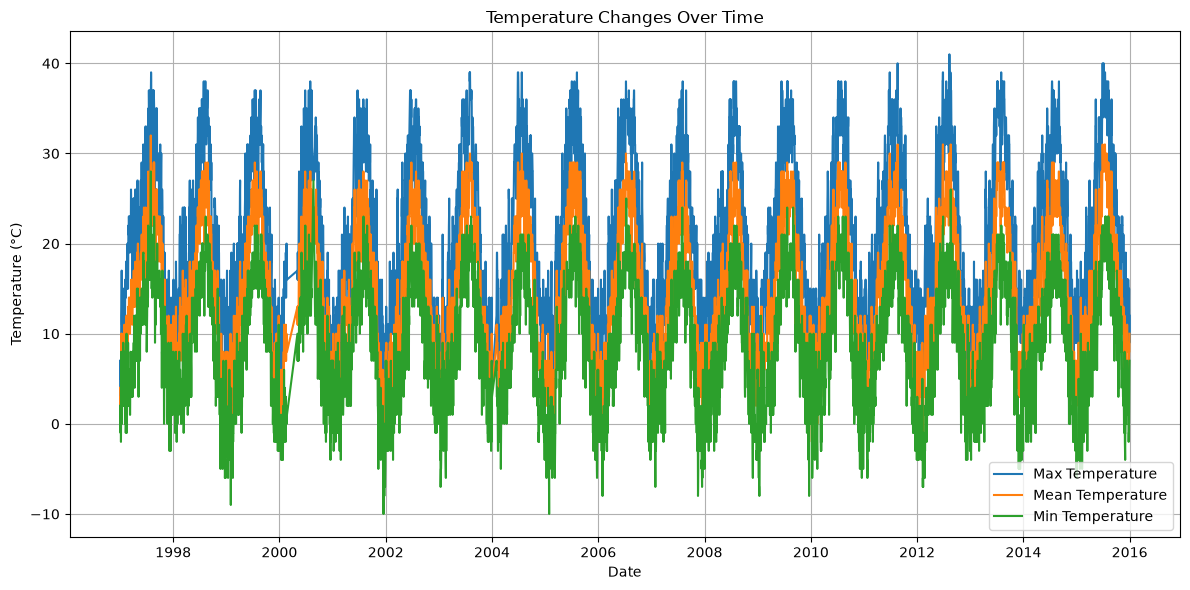

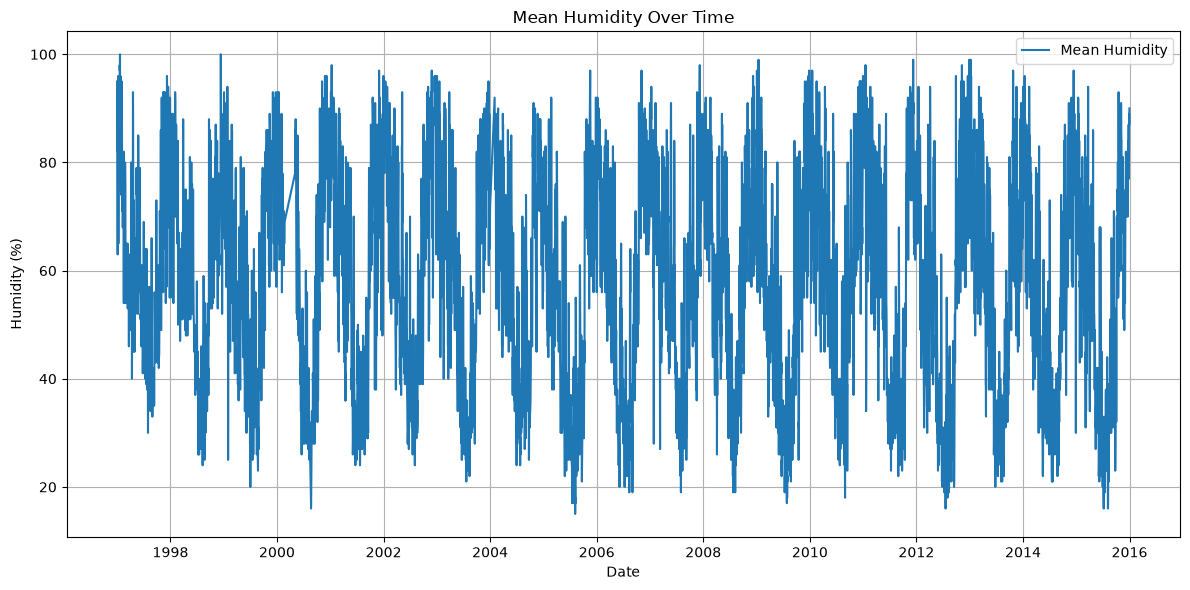

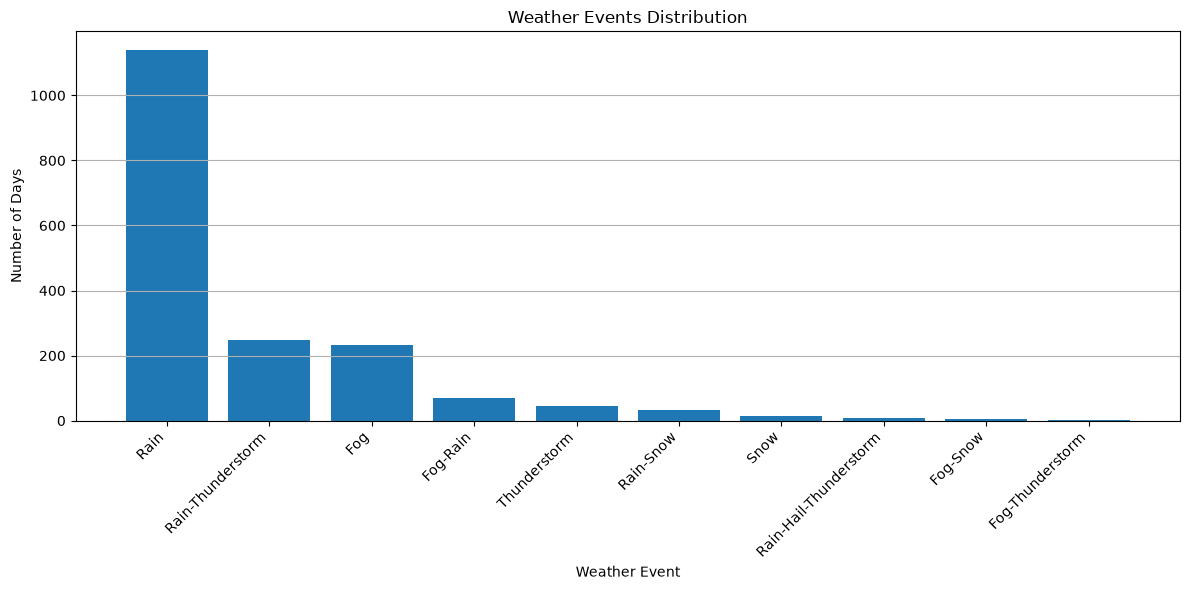

In [12]:
def visualize_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib. Use more then one visualization. 
    Save the results in the repository.

    Args:
        None: None.

    Returns:
        None: None.
    """
    df = pd.read_csv("resources/weather.csv")

    df["CET"] = pd.to_datetime(df["CET"])

    plt.figure(figsize=(12, 6))

    plt.plot(df["CET"], df["Max TemperatureC"], label="Max Temperature")
    plt.plot(df["CET"], df["Mean TemperatureC"], label="Mean Temperature")
    plt.plot(df["CET"], df["Min TemperatureC"], label="Min Temperature")

    plt.title("Temperature Changes Over Time")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig("images/temperature_changes.png")
    plt.show()


    plt.figure(figsize=(12, 6))

    plt.plot(df["CET"], df[" Mean Humidity"], label="Mean Humidity")

    plt.title("Mean Humidity Over Time")
    plt.xlabel("Date")
    plt.ylabel("Humidity (%)")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig("images/humidity_changes.png")
    plt.show()


    events = df[" Events"].dropna()
    events = events.value_counts().head(10)

    plt.figure(figsize=(12, 6))

    plt.bar(events.index, events.values)

    plt.title("Weather Events Distribution")
    plt.xlabel("Weather Event")
    plt.ylabel("Number of Days")

    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y")
    plt.tight_layout()

    plt.savefig("images/weather_events.png")
    plt.show()

visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

In [7]:
%pip install "kagglehub[pandas-datasets]" scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [18]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def impute_data(df):
    """
    Parse the data from file and impute missing values using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with imputed values.
    """
    df = df.copy()

    df["lunch"] = df["lunch"].fillna(df["lunch"].mode()[0])

    return df

def normalize_data(df):
    """
    Normalize the data using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with normalized values.
    """
    df = df.copy()

    columns = ["math score", "reading score", "writing score"]

    for column in columns:
        df[column] = (
            (df[column] - df[column].min())
            / (df[column].max() - df[column].min())
        )

    return df

def visualize_data(df):
    """
    Visualize the data using Matplotlib. Use more then one visualization. 
    Save the results in the repository.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        None: None.
    """
    plt.figure(figsize=(12, 6))

    plt.hist(df["math score"], bins=20, alpha=0.5, label="Math")
    plt.hist(df["reading score"], bins=20, alpha=0.5, label="Reading")
    plt.hist(df["writing score"], bins=20, alpha=0.5, label="Writing")

    plt.title("Distribution of Normalized Test Scores")
    plt.xlabel("Normalized Score")
    plt.ylabel("Number of Students")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig("images/normalized_scores_distribution.png")
    plt.show()


    plt.figure(figsize=(12, 6))

    plt.scatter(df["reading score"], df["writing score"], alpha=0.5)

    plt.title("Reading vs Writing Scores")
    plt.xlabel("Normalized Reading Score")
    plt.ylabel("Normalized Writing Score")

    plt.grid(True)
    plt.tight_layout()

    plt.savefig("images/reading_writing_scatter.png")
    plt.show()

In [19]:
df = load_dataset(
    'ilayaraja07/data-cleaning-feature-imputation',
    'Students_Performance_knn.csv'
)

print(df.head())
print(df.shape)
print(df.isnull().sum())

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
(1000, 8)
gender                          0
race/ethnicity                  0
parental level of education     0
lunch                          25
test preparat

In [20]:
df_imputed = impute_data(df)

print("Most frequent lunch category:", df["lunch"].mode()[0])
print("Missing values before:", df["lunch"].isnull().sum())
print("Missing values after:", df_imputed["lunch"].isnull().sum())

Most frequent lunch category: standard
Missing values before: 25
Missing values after: 0


In [21]:
df_normalized = normalize_data(df_imputed)

print(df_normalized[
    ["math score", "reading score", "writing score"]
].head())

   math score  reading score  writing score
0        0.72       0.662651       0.711111
1        0.69       0.879518       0.866667
2        0.90       0.939759       0.922222
3        0.47       0.481928       0.377778
4        0.76       0.734940       0.722222


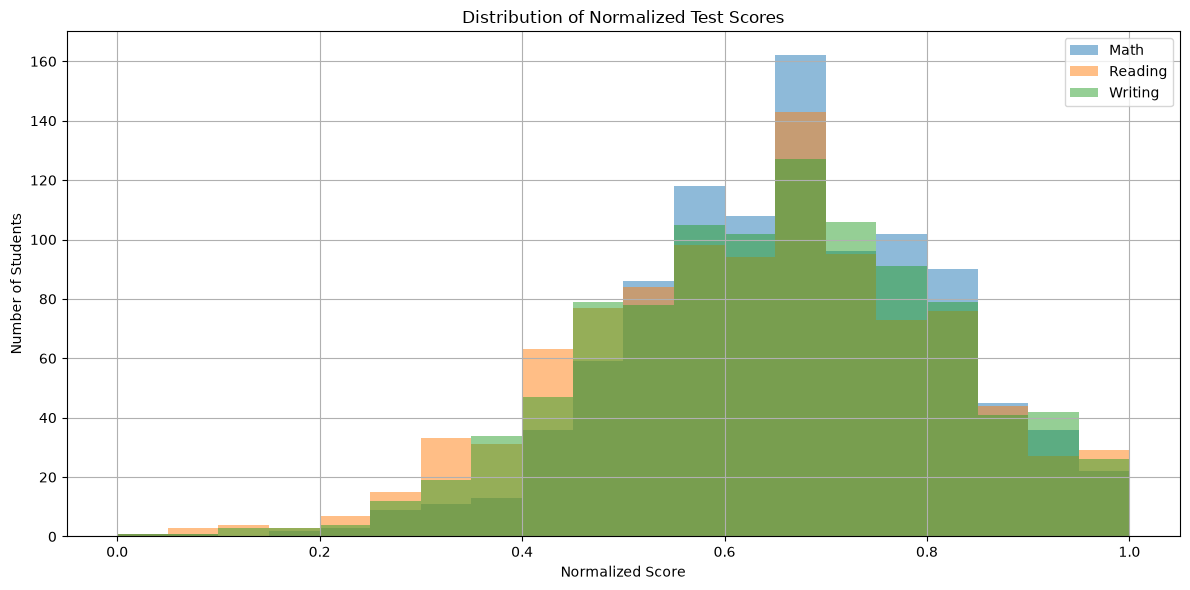

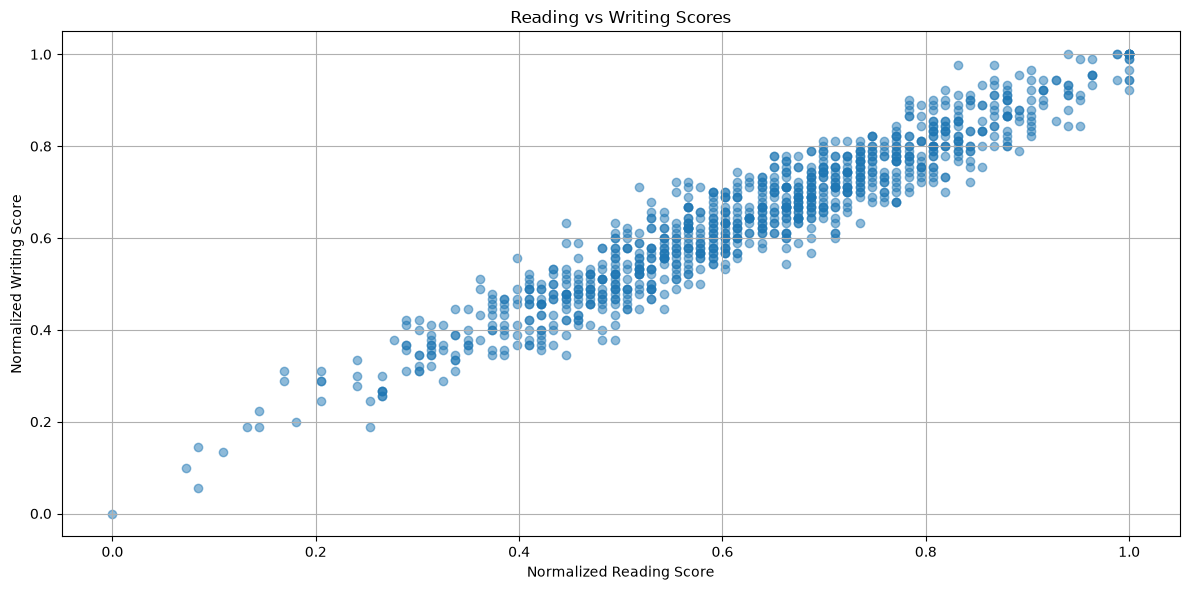

In [22]:
visualize_data(df_normalized)